In [2]:
from cProfile import label

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.parquet as pq

from analiza_czasow_przybycia_tranzakcji import czasy_wykopania

In [3]:
path = 'data/bitcoin_data.parquet'
data_raw = pq.read_pandas(path)

In [6]:
kolumny = [
    'mined_at',
    'block_height',
]

data = data_raw.select(kolumny).to_pandas()


data

,mined_at,block_height
0,2025-09-09 22:22:27,913970
1,2025-09-09 22:22:26,913970
2,2025-09-09 22:22:26,913970
3,2025-09-09 22:22:26,913970
4,2025-09-09 22:22:25,913970
...,...,...
11110272,2025-08-03 21:54:38,908462
11110273,2025-08-03 21:54:39,908462
11110274,2025-08-03 21:54:38,908462
11110275,2025-08-03 21:54:41,908462


In [7]:
czasy_wykopania = data['mined_at'].unique()
czasy_wykopania

<DatetimeArray>
['2025-09-09 22:22:27', '2025-09-09 22:22:26', '2025-09-09 22:22:25',
 '2025-09-09 22:22:24', '2025-09-11 20:57:17', '2025-09-11 20:57:18',
 '2025-09-11 20:57:15', '2025-09-11 20:57:14', '2025-09-11 20:57:20',
 '2025-09-11 20:57:19',
 ...
 '2025-08-03 10:26:11', '2025-08-03 21:54:45', '2025-08-03 21:54:44',
 '2025-08-03 21:54:40', '2025-08-03 21:54:42', '2025-08-03 21:54:39',
 '2025-08-03 21:54:38', '2025-08-03 21:54:41', '2025-08-03 21:54:37',
 '2025-08-03 21:54:43']
Length: 69663, dtype: datetime64[ns]

In [8]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Jeden rekord na wysokość bloku
bloki = (
    data[['block_height', 'mined_at']]
    .dropna()
    .assign(
        mined_at=lambda x: pd.to_datetime(x['mined_at'])
    )
    .groupby('block_height', as_index=False)
    .agg(czas_bloku=('mined_at', 'min'))
    .sort_values('block_height')
    .reset_index(drop=True)
)

# Różnice wysokości sąsiednich obserwacji
bloki['roznica_wysokosci'] = (
    bloki['block_height'].diff()
)

# Różnice czasu w minutach
bloki['odstep_min'] = (
    bloki['czas_bloku']
    .diff()
    .dt.total_seconds() / 60
)

# Tylko bloki o kolejnych wysokościach
sasiednie = bloki['roznica_wysokosci'] == 1

print("Liczba bloków:", len(bloki))
print("Pary kolejnych bloków:", sasiednie.sum())
print("Luki w wysokościach:",
      (bloki['roznica_wysokosci'] > 1).sum())
print("Odstępy <= 0:",
      (sasiednie & (bloki['odstep_min'] <= 0)).sum())

# Poprawne dodatnie odstępy
odstepy = bloki.loc[
    sasiednie & (bloki['odstep_min'] > 0),
    'odstep_min'
]

odstepy.describe()


Liczba bloków: 5965
Pary kolejnych bloków: 5882
Luki w wysokościach: 82
Odstępy <= 0: 1


count    5881.000000
mean        9.895548
std         9.888352
min         0.050000
25%         2.900000
50%         7.000000
75%        13.416667
max        96.766667
Name: odstep_min, dtype: float64

In [9]:
statystyki = pd.Series({
    'Liczba odstępów': len(odstepy),
    'Średnia [min]': odstepy.mean(),
    'Mediana [min]': odstepy.median(),
    'Odchylenie standardowe': odstepy.std(),
    'Wariancja': odstepy.var(),
    'Minimum': odstepy.min(),
    'Maksimum': odstepy.max(),
    'Q05': odstepy.quantile(0.05),
    'Q25': odstepy.quantile(0.25),
    'Q75': odstepy.quantile(0.75),
    'Q95': odstepy.quantile(0.95),
    'CV': odstepy.std() / odstepy.mean()
})

display(statystyki)

Liczba odstępów           5881.000000
Średnia [min]                9.895548
Mediana [min]                7.000000
Odchylenie standardowe       9.888352
Wariancja                   97.779503
Minimum                      0.050000
Maksimum                    96.766667
Q05                          0.600000
Q25                          2.900000
Q75                         13.416667
Q95                         29.533333
CV                           0.999273
dtype: float64

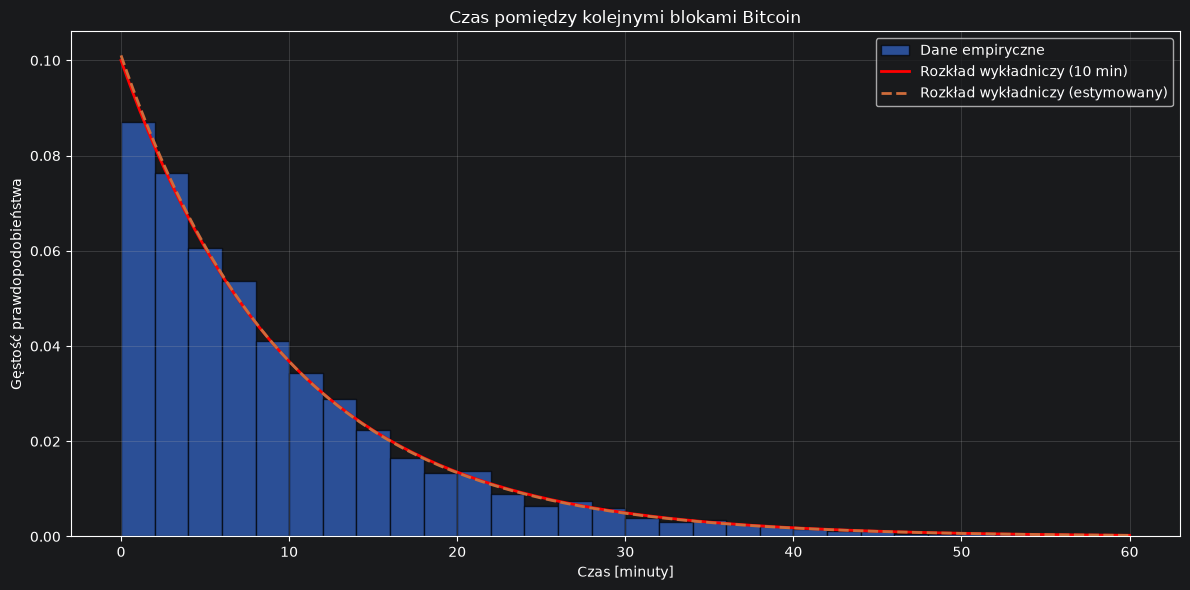

In [10]:

fig, ax = plt.subplots(figsize=(12, 6))

# Histogram dla czasów 0-60 minut
bins = np.arange(0, 62, 2)
wagi = np.ones(len(odstepy)) / (len(odstepy) * 2)

ax.hist(
    odstepy,
    bins=bins,
    weights=wagi,
    alpha=0.65,
    edgecolor='black',
    label='Dane empiryczne'
)

x = np.linspace(0, 60, 500)

# Rozkład teoretyczny
ax.plot(
    x,
    stats.expon.pdf(x, scale=10),
    color='red',
    linewidth=2,
    label='Rozkład wykładniczy (10 min)'
)

# Rozkład z estymowaną średnią
ax.plot(
    x,
    stats.expon.pdf(x, scale=odstepy.mean()),
    linestyle='--',
    linewidth=2,
    label='Rozkład wykładniczy (estymowany)'
)

ax.set_title('Czas pomiędzy kolejnymi blokami Bitcoin')
ax.set_xlabel('Czas [minuty]')
ax.set_ylabel('Gęstość prawdopodobieństwa')
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [11]:
prog1 = pd.Timestamp('2025-09-01 20:44:17')
prog2 = pd.Timestamp('2025-09-15 20:44:17')
prog3 = pd.Timestamp('2025-09-26 02:44:17')

bloki['okres'] = pd.cut(
    bloki['czas_bloku'],
    bins=[
        pd.Timestamp('1900-01-01'),
        prog1,
        prog2,
        prog3,
        pd.Timestamp('2100-01-01')
    ],
    labels=['Okres 1', 'Okres 2', 'Okres 3', 'Okres 4'],
    right=False
)

# Pomijamy odstępy przecinające granice okresów
poprawne = (
    (bloki['roznica_wysokosci'] == 1) &
    (bloki['odstep_min'] > 0) &
    (bloki['okres'] == bloki['okres'].shift(1))
)

porownanie = (
    bloki.loc[poprawne]
    .groupby('okres', observed=True)['odstep_min']
    .agg(['count', 'mean', 'median', 'std', 'var'])
)

porownanie['CV'] = (
    porownanie['std'] / porownanie['mean']
)

display(porownanie.round(3))

,count,mean,median,std,var,CV
okres,,,,,,
Okres 1,2816,9.856,6.950,9.996,99.928,1.014
Okres 2,1059,9.393,6.733,8.915,79.472,0.949
Okres 3,274,9.568,7.033,9.088,82.600,0.950
Okres 4,1732,10.319,7.200,10.377,107.685,1.006


In [12]:
D, p_value = stats.kstest(
    odstepy,
    'expon',
    args=(0, 10)
)

print("Statystyka KS:", D)
print("p-value:", p_value)

Statystyka KS: 0.013849957878417288
p-value: 0.2073354515786756
